# Parsing one page: Docling, PaddleOCR-VL and Qwen VL

Notebook demo of the AI2Future workshop *Can We Rely on Extracted Documents? Parsing Methods Compared*
(Filip Pavičić, Atomic Intelligence).

We follow one page of a synthetic lab report through a parsing pipeline: the regions a parser finds, the
Markdown it writes, the errors it makes and the checks that catch some of them. Docling runs here, on the
CPU. PaddleOCR-VL and Qwen VL need a GPU, so their outputs on the same page are loaded from `data/cached/`.

Run the cells from top to bottom. Sections 5 and 7 can be skipped. Loading files and drawing are in
`src/dudemo/`; everything the demo is about is in the cells below.

## Setup

On Colab, the first cell clones the repository and installs the dependencies, which takes a few minutes.
Locally, install as described in the README and start Jupyter from the repository.

In [1]:
import subprocess
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and Path.cwd().name != "document-understanding-demo":
    if not Path("document-understanding-demo").exists():
        !git clone --quiet --depth 1 https://github.com/Atomic-Intelligence/document-understanding-demo.git
    %cd document-understanding-demo
    # pip warns that google-colab pins an older requests than Docling needs; Colab works with the
    # newer one, so the output is shown only if the install fails.
    pip = subprocess.run([sys.executable, "-m", "pip", "install", "--quiet", "--progress-bar", "off", "-e", "."],
                         capture_output=True, text=True)
    if pip.returncode != 0:
        print(pip.stdout, pip.stderr)
        raise RuntimeError("Installing the dependencies failed; pip's output is above.")
    print("Dependencies installed.")

# The repository root, whether Jupyter was started in notebooks/ or in the root
ROOT = Path.cwd() if (Path.cwd() / "src" / "dudemo").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

In [2]:
import difflib
import re
import time

import pandas as pd
from PIL import Image, ImageOps

from dudemo import data, quiet, show

quiet()   # no model-loading logs in the output

## 1. The page

A synthetic Croatian lab report from our page generator: patient fields, two tables of results with
units and reference ranges, and a flag column (H for high, L for low). The page is an image, so there is
no text layer to copy: every parser has to read the pixels.

Left: the regions of the page, coloured by type. Right: the Markdown a perfect parser would write. This
is the ground truth every parser below is held against.

Parametar,Rezultat,Jedinica,Referentni interval,Flag
Leukociti (WBC),"5,8",10⁹/L,"3,9 - 10,0",
Eritrociti (RBC),"4,52",10¹²/L,"3,80 - 5,10",
Hemoglobin (Hgb),145,g/L,117 - 157,
Hematokrit (Hct),"0,43",L/L,"0,35 - 0,47",
MCV,"95,1",fL,"80,0 - 97,0",
MCH,"32,0",pg,"27,0 - 34,0",
MCHC,337,g/L,320 - 360,
Trombociti (PLT),321,10⁹/L,158 - 424,
Neutrofilni granulociti,"58,0",%,"40,0 - 70,0",
Limfociti,"35,0",%,"20,0 - 45,0",

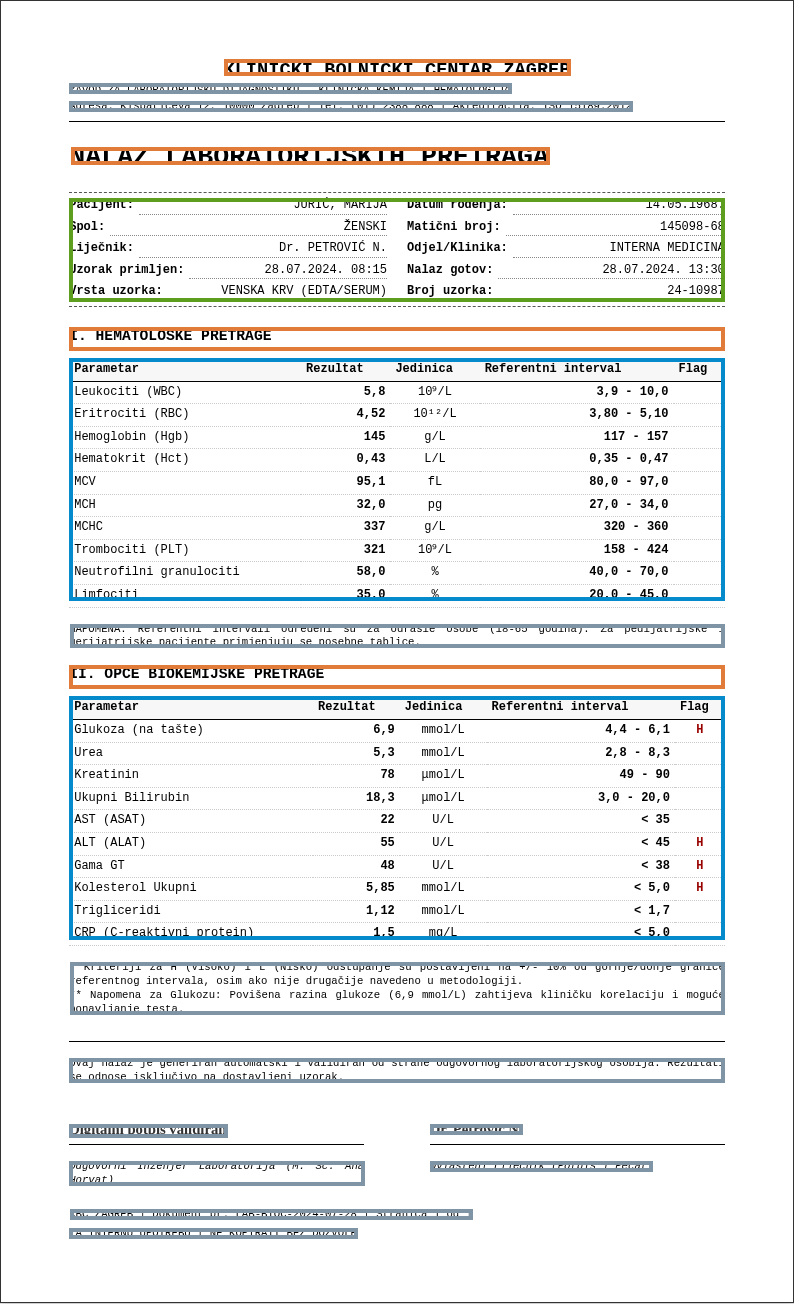

In [3]:
PAGE = "lab_report_1"
truth = data.ground_truth(PAGE)
show.parse(truth)

## 2. Parse it with Docling

Docling is a pipeline of separate models, one for each step on the slides:

1. **Detection**: a layout model (Heron) finds the regions of the page and their type.
2. **Recognition**: OCR (RapidOCR) reads the text; TableFormer rebuilds each table's rows and columns.
3. **Transformation**: Docling assembles everything into one document and writes Markdown, HTML or JSON.

No part of it generates text: it can misread a character, but it cannot invent a sentence. These are
the settings we used in the evaluation. The first run downloads the models.

In [4]:
from docling.datamodel.base_models import InputFormat
from docling.datamodel.pipeline_options import (LayoutObjectDetectionOptions, PdfPipelineOptions,
                                                RapidOcrOptions, TableFormerMode, TableStructureOptions)
from docling.document_converter import DocumentConverter, ImageFormatOption, PdfFormatOption

options = PdfPipelineOptions(
    layout_options=LayoutObjectDetectionOptions.from_preset("layout_heron_default"),  # 1. detection
    do_ocr=True,
    ocr_options=RapidOcrOptions(backend="torch"),                                     # 2. recognition: text
    do_table_structure=True,
    table_structure_options=TableStructureOptions(mode=TableFormerMode.ACCURATE),     # 2. recognition: tables
    generate_page_images=True,                                                       # to draw the regions
)
converter = DocumentConverter(format_options={
    InputFormat.IMAGE: ImageFormatOption(pipeline_options=options),
    InputFormat.PDF: PdfFormatOption(pipeline_options=options),
})
converter.initialize_pipeline(InputFormat.IMAGE)   # loads the models
print("Docling is ready.")

Docling is ready.


In [5]:
start = time.perf_counter()
doc = converter.convert(data.page_path(PAGE)).document
print(f"Docling read the page in {time.perf_counter() - start:.0f} seconds on this machine.")

Docling read the page in 26 seconds on this machine.


**1. Detection.** Every item Docling found has a label from the layout model and a box on the page.
These are the first ones, in reading order:

In [6]:
for item, _level in list(doc.iterate_items())[:12]:
    print(f"{item.label.value:16}", getattr(item, "text", "")[:60])

section_header   KLINIČKI BOLNIČKI CENTAR ZAGREB
text             ZAVOD ZA LABORATORIJSKU DIJAGNOSTIKU - KLINIČKA KEMIJAI HEMA
text             Adr 1 1    11     1 1   012
section_header   NALAZ LABORATORIJSKIH PRETRAGA
text             Pacijent:
text             JURIC, MARIJA
text             Datum rođenja:
text             Spol:
text             ŽENSKI
text             Matični broj:
text             Liječnik:
text             Dr. PETROVIĆ N.


**2. Recognition.** TableFormer turned the second table into rows and columns. Compare it with the
page above.

In [7]:
doc.tables[1].export_to_dataframe(doc=doc)

,Parametar,Rezultat,Jedinica,Referentni interval,Flag,Flag
0,Glukoza (na tašte),"6,9",mmol/L,"4,4","6,1",H
1,Urea,"5,3",mmol/L,"2,8","8,3",
2,Kreatinin,78,μmol/L,49,90,
3,Ukupni Bilirubin,"18,3",μmol/L,"3,0 -","20,0",
4,AST (ASAT),22,U/L,,< 35,
5,ALT (ALAT),55,U/L,,> 45,H
6,Gama GT,48,U/L,,> 38,H
7,Kolesterol Ukupni,"5,85",mmol/L,,"< 5,0",H
8,Trigliceridi,"1,12",mmol/L,,"< 1,7",
9,CRP (C-reaktivni protein),"1,5",mg/L,,"< 5,0",


**3. Transformation.** The same table as Markdown, the form most pipelines store and send on to an
LLM:

In [8]:
print(doc.tables[1].export_to_markdown(doc=doc))

| Parametar                 | Rezultat   | Jedinica   | Referentni interval   | Flag   | Flag   |
|---------------------------|------------|------------|-----------------------|--------|--------|
| Glukoza (na tašte)        | 6,9        | mmol/L     | 4,4                   | 6,1    | H      |
| Urea                      | 5,3        | mmol/L     | 2,8                   | 8,3    |        |
| Kreatinin                 | 78         | μmol/L     | 49                    | 90     |        |
| Ukupni Bilirubin          | 18,3       | μmol/L     | 3,0 -                 | 20,0   |        |
| AST (ASAT)                | 22         | U/L        |                       | < 35   |        |
| ALT (ALAT)                | 55         | U/L        |                       | > 45   | H      |
| Gama GT                   | 48         | U/L        |                       | > 38   | H      |
| Kolesterol Ukupni         | 5,85       | mmol/L     |                       | < 5,0  | H      |
| Trigliceridi      

The whole page: the regions Docling found, coloured by type, next to its Markdown, rendered.

Parametar,Rezultat,Jedinica,Referentni interval,,Flag
Leukociti (WBC),"5,8",109/L,"3,9","10,0",
Eritrociti (RBC),"4,52",1012/L,"3,80 - 5,10",,
Hemoglobin (Hgb),145,g/L,,117 - 157,
Hematokrit (Hct),"0,43",L/L,"0,35 - 0,47",,
MCV,"95,1",fL,"80,0 - 97,0",,
MCH,"32,0",pg,"27,0 - 34,0",,
MCHC,337,g/L,,320 - 360,
Trombociti (PLT),321,109/L,,158 - 424,
Neutrofilnigranulociti,"58,0",%,"40,0 - 70,0",,
Limfociti,"35,0",%,"20,0 - 45,0",,

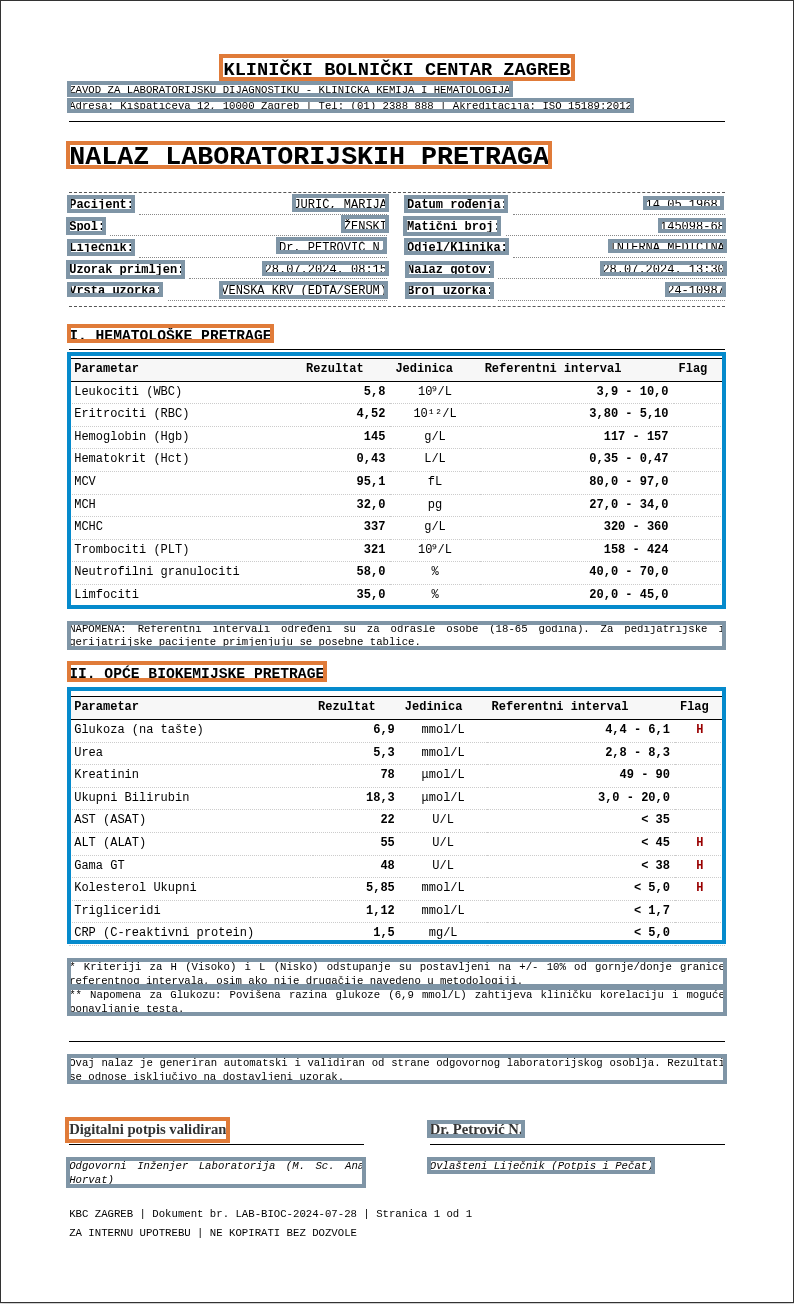

In [9]:
docling = data.from_docling(doc)
show.parse(docling)

**Question for the room:** what did Docling get wrong in the two tables?

## 3. The same page, three other parsers

Their outputs were made on a GPU and are loaded from `data/cached/`.

**PaddleOCR-VL** works in two stages: a layout detector finds and labels the blocks, then a small
vision-language model reads each block on its own. The blocks it returned, in reading order:

In [10]:
for block in data.paddle_blocks(PAGE)[:10]:
    print(f"{block['label']:16}", repr(block["content"][:60]))

header           'KLINIČKI BOLNIĚKI CENTAR ZAGREB'
header           'ZAVOD ZA LABORATORIJSKU DIJAGNOSTIKU - KLINIĘKA KEMIJA I HEM'
header           'Adresa: Kišpatićeva 12, 10000 Zagreb | Tel: (01) 2388 888 | '
paragraph_title  'NALAZ LABORATORIJSKIH PRETRAGA'
table            '<table><tr><td>Pacijent:</td><td>JURIĆ, MARIJA</td><td>Datum'
paragraph_title  'I. HEMATOLOŠKE PRETRAGE'
table            '<table><tr><td>Parameter</td><td>Rezultat</td><td>Jedinica</'
vision_footnote  'NAPOMENA: Referentni intervali određeni su za odrasle osobe '
paragraph_title  'II. OPCE BIOKEMIJSKE PRETRAGE'
table            '<table><tr><td>Parameter</td><td>Rezultat</td><td>Jedinica</'



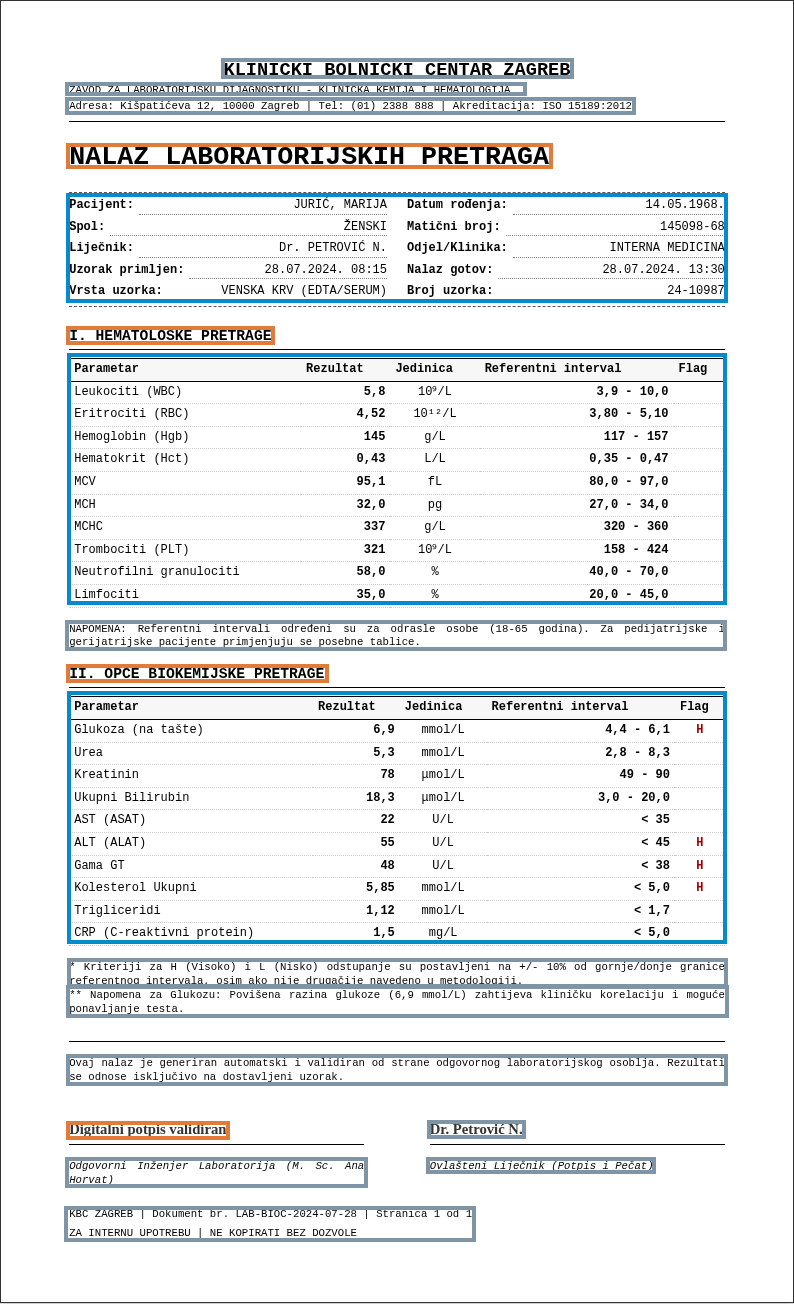

In [11]:
show.parse(data.cached(PAGE, "paddleocr_vl"))

**Qwen VL** reads the whole page in one pass and writes everything at once. With one long prompt we
ask it to write each block as a tag: its type, its box as `<location>`, and its text. The prompt is part
of the method: change it and the output changes. The fine-tuned model's answer, as written:

In [12]:
print(data.first_blocks(data.raw_text(PAGE, "qwen_finetuned"), 5))

<heading>
<location><x1>225.0</x1><y1>62.0</y1><x2>571.0</x2><y2>75.0</y2></location>
<text>
KLINIČKI BOLNIČKI CENTAR ZAGREB
</text>
</heading>

<paragraph>
<location><x1>69.0</x1><y1>86.0</y1><x2>512.0</x2><y2>94.0</y2></location>
<text>
ZAVOD ZA LABORATORIJSKU DIJAGNOSTIKU - KLINIČKA KEMIJA I HEMATOLOGIJA
</text>
</paragraph>

<paragraph>
<location><x1>69.0</x1><y1>103.0</y1><x2>633.0</x2><y2>111.0</y2></location>
<text>
Adresa: Kišpatićeva 12, 10000 Zagreb | Tel: (01) 2388 888 | Akreditacija: ISO 15189:2012
</text>
</paragraph>

<heading>
<location><x1>71.0</x1><y1>148.0</y1><x2>550.0</x2><y2>166.0</y2></location>
<text>
NALAZ LABORATORIJSKIH PRETRAGA
</text>
</heading>

<key_value_section>
<location><x1>69.0</x1><y1>199.0</y1><x2>725.0</x2><y2>304.0</y2></location>
<text>
{'key': 'Pacijent:', 'value': 'JURIĆ, MARIJA'}
{'key': 'Datum rođenja:', 'value': '14.05.1968.'}
{'key': 'Spol:', 'value': 'ŽENSKI'}
{'key': 'Matični broj:', 'value': '145098-68'}
{'key': 'Liječnik:', 'value': 'Dr

The general model got the same prompt and the same page. Look at its `<location>` tags, and at the
patient's registration number (*Matični broj*):

In [13]:
print(data.first_blocks(data.raw_text(PAGE, "qwen_base"), 5))

```html
<heading>
<location><x1>10.0</x1><y1>20.0</y1><x2>700.0</y2>700.0</y2></location>
<text>KLINIČKI BOLNIČKI CENTAR ZAGREB</text>
</heading>

<paragraph>
<location><x1>10.0</x1><y1>80.0</y1><x2>700.0</y2>700.0</y2></location>
<text>ZAVOD ZA LABORATORIJSKU DIJAGNOSTIKU - KLINIČKA KEMIJA I HEMATOLOGIJA</text>
</paragraph>

<key_value_section>
<location><x1>10.0</x1><y1>100.0</y1><x2>700.0</y2>700.0</y2></location>
<text>Adresa: Kišpatiće 12, 10000 Zagreb | Tel: (01) 2388 888 | Akreditacija: ISO 15189:2012</text>
</key_value_section>

<paragraph>
<location><x1>10.0</x1><y1>120.0</y1><x2>700.0</y2>700.0</y2></location>
<text>NALAZ LABORATORIJSKIH PRETRAGA</text>
</paragraph>

<key_value_section>
<location><x1>10.0</x1><y1>140.0</y1><x2>700.0</y2>700.0</y2></location>
<text>Pacijent: JURIĆ, MARIJA<br>Spol: ŽENSKI<br>Matični broj: 145998-68<br>Liječnik: Dr. PETROVIĆ N.<br>Odjel/Klinika: INTERNA MEDICINA<br>Uzorak primljen: 28.07.2024. 08:15<br>Nalaz gotov: 28.07.2024. 13:30<br>Vrsta uzo

Its boxes are not read from the page, and the tags themselves are broken. Both models, drawn:

Parametar,Rezultat,Jedinica,Referentni interval,Flag
Leukociti (WBC),"5,8",10^9/L,"3,9 - 10,0",
Eritrociti (RBC),"4,52",10^12/L,"3,80 - 5,10",
Hemoglobin (Hgb),145,g/L,117 - 157,
Hematokrit (Hct),"0,43",L/L,"0,35 - 0,47",
MCV,"95,1",fL,"80,0 - 97,0",
MCH,"32,0",pg,"27,0 - 34,0",
MCHC,337,g/L,320 - 360,
Trombociti (PLT),321,10^9/L,158 - 424,
Neutrofilni granulociti,"58,0",%,"40,0 - 70,0",
Limfociti,"35,0",%,"20,0 - 45,0",

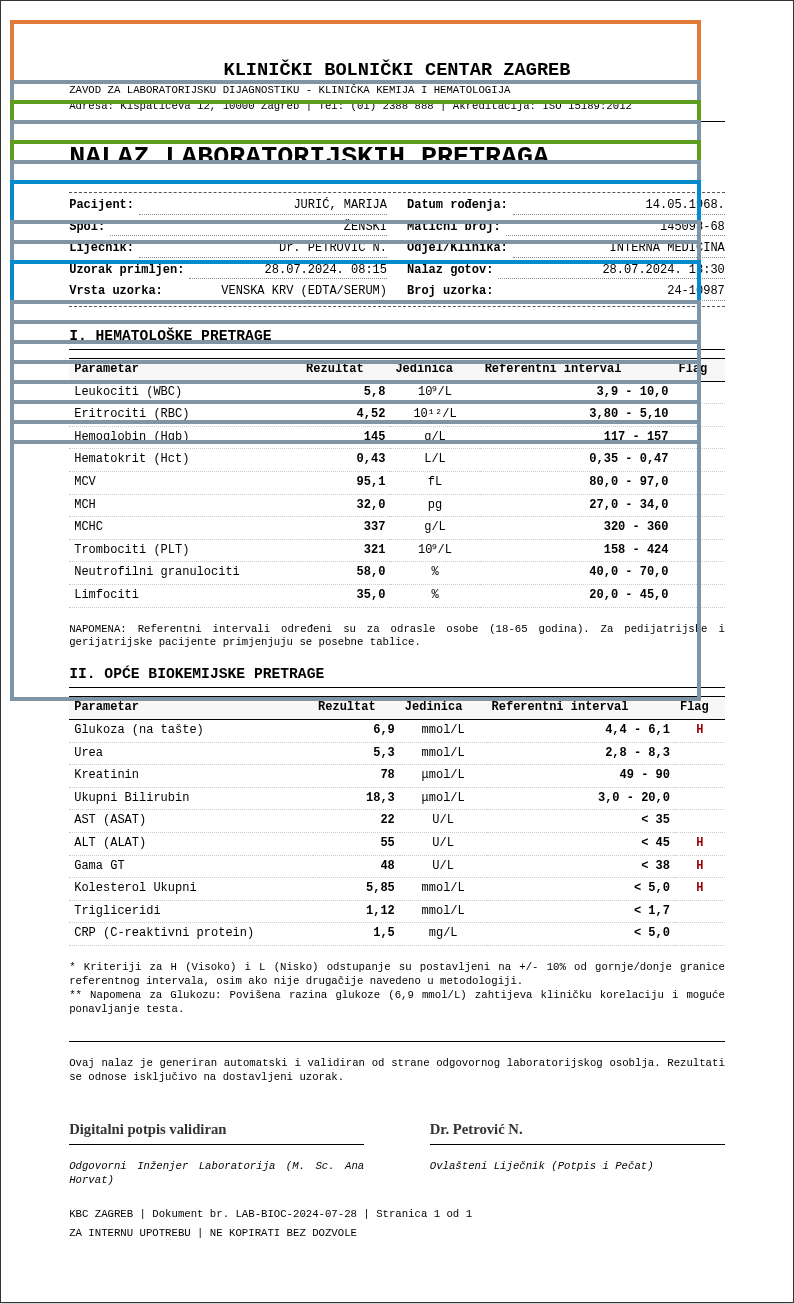

Parametar,Rezultat,Jedinica,Referentni interval,Flag
Leukociti (WBC),"5,8",10⁹/L,"3,9 - 10,0",
Eritrociti (RBC),"4,52",10¹²/L,"3,80 - 5,10",
Hemoglobin (Hgb),145,g/L,117 - 157,
Hematokrit (Hct),"0,43",L/L,"0,35 - 0,47",
MCV,"95,1",fL,"80,0 - 97,0",
MCH,"32,0",pg,"27,0 - 34,0",
MCHC,337,g/L,320 - 360,
Trombociti (PLT),321,10⁹/L,158 - 424,
Neutrofilni granulociti,"58,0",%,"40,0 - 70,0",
Limfociti,"35,0",%,"20,0 - 45,0",

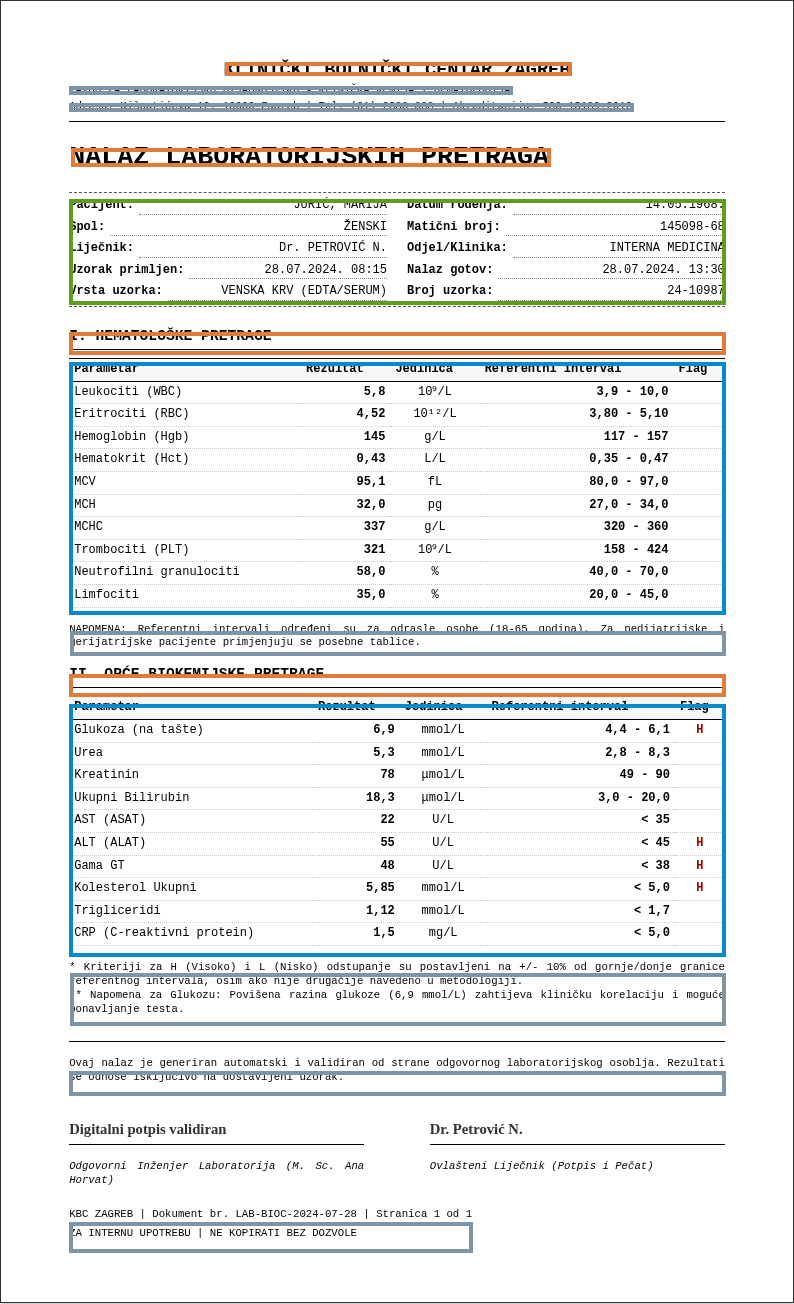

In [14]:
for model in ["qwen_base", "qwen_finetuned"]:
    show.parse(data.cached(PAGE, model))

**Question for the room:** which of the four would you start with for documents like this one?

## 4. Three kinds of error

Each example shows the row on the page, the row as the page has it, and the row as the parser wrote it.
Cells that are not on the page are marked red.

- **Visibly broken**: anyone reading the output sees it.
- **Structure wrong**: the text may be right, but the shape is not.
- **Passes as correct**: a wrong value that looks right. This is the dangerous kind.

Parametar,Rezultat,Jedinica,Referentni interval,Flag
Leukociti (WBC),"5,8",10⁹/L,"3,9 - 10,0",
Parameter,Rezultat,Jedinica,Referentni interval,Flag
Leukociti (WBC),"5,8",$ 10^{{9}}/L $,"3,9 - 10,0",

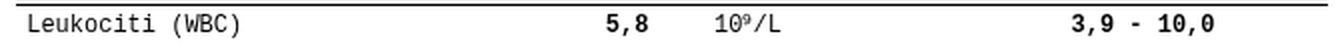


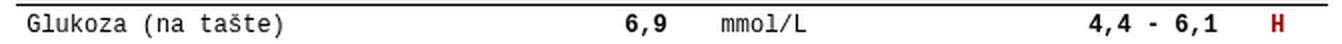


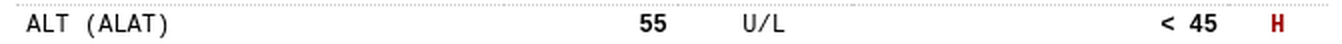

In [15]:
outputs = {"docling": docling, **{model: data.cached(PAGE, model) for model in data.CACHED_MODELS}}
for example in data.examples():
    show.error(example, outputs[example["model"]], truth)

## 5. General and fine-tuned Qwen VL

The same model, prompt and settings; only the weights differ. On a second report, every region of the
page that the model missed is outlined in dashed red.

*Can be skipped.*


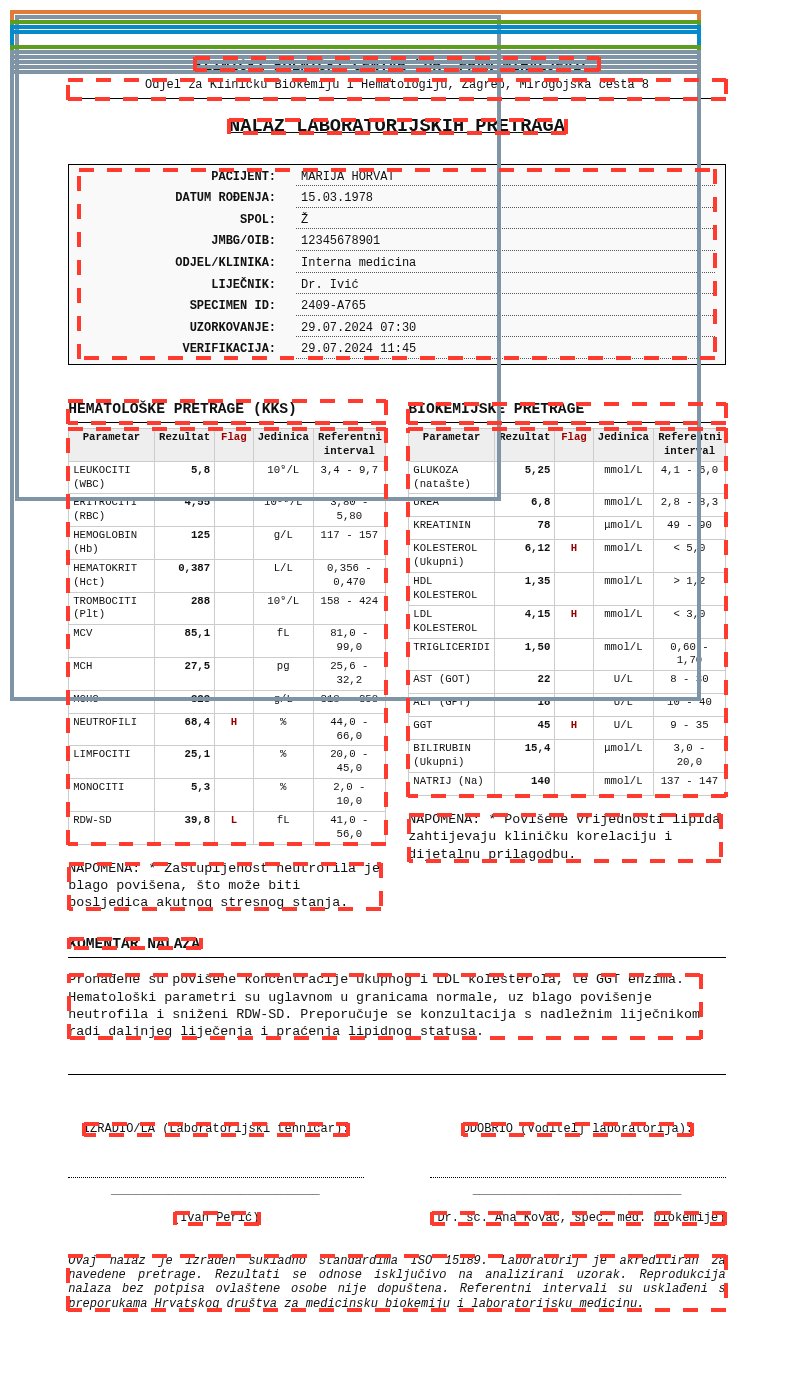
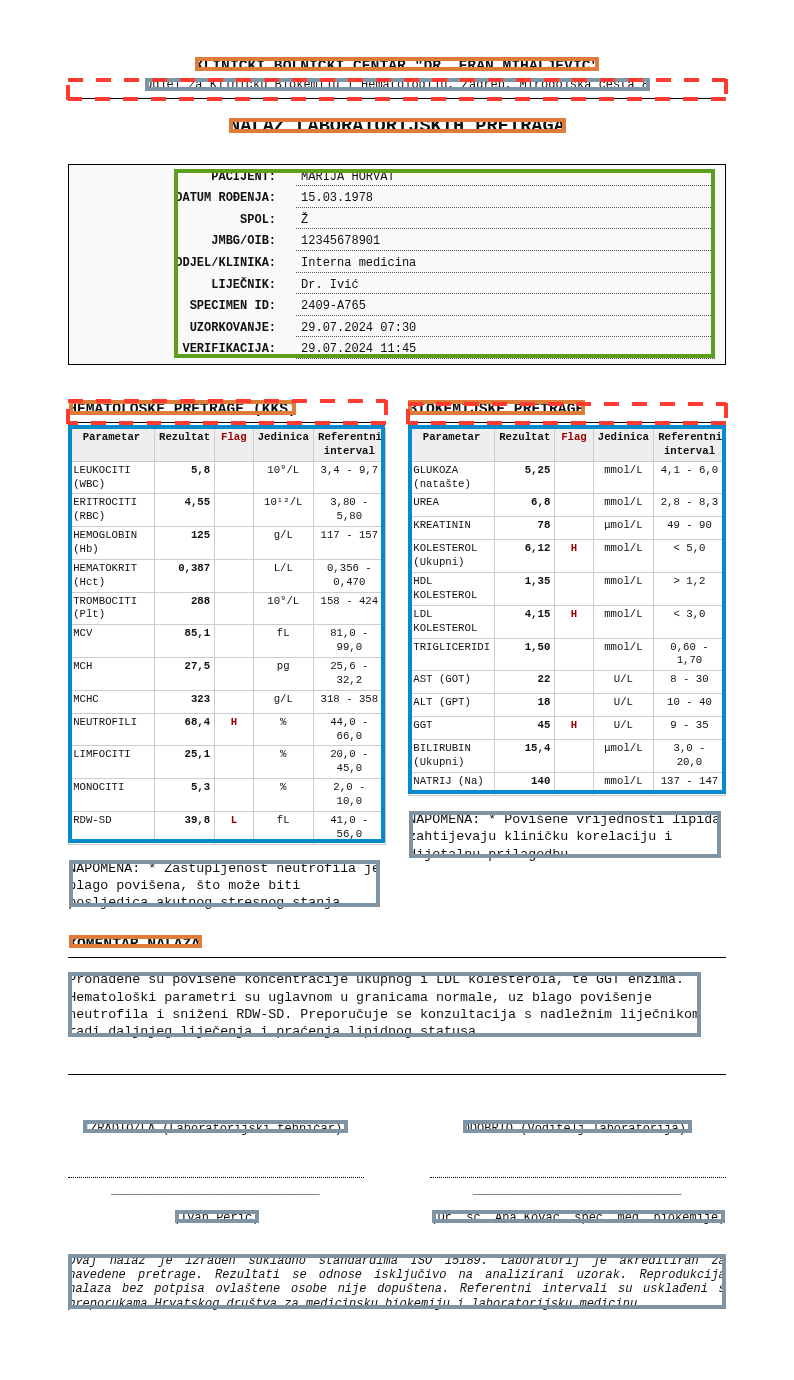

In [16]:
PAGE_2 = "lab_report_2"
show.side_by_side(data.cached(PAGE_2, "qwen_base"), data.cached(PAGE_2, "qwen_finetuned"),
                  missed_from=data.ground_truth(PAGE_2))

Fine-tuning taught the model the format: regions in the right place, tables as tables. It did not make
every value right: on this page the fine-tuned model writes the doctor *Dr. Ivić* as *Dr. Tić*, a
well-formed name that nothing in the output marks as wrong.

## 6. Checks after extraction

A check reads only the parser's output, with no ground truth, and sends what looks wrong to a person.
Three rules for lab results, a few lines each:

In [17]:
UNITS = {"10⁹/L", "10¹²/L", "g/L", "mmol/L", "µmol/L", "μmol/L", "U/L", "%", "fL", "pg", "L/L", "mg/L"}
NUMBER = r"\d+(?:,\d+)?"
RANGE = re.compile(rf"(?P<low>{NUMBER}) - (?P<high>{NUMBER})|(?P<sign>[<>]) (?P<limit>{NUMBER})")


def number(text):
    return float(text.replace(",", "."))


def unit_is_known(unit):
    return unit in UNITS


def range_looks_like_a_range(reference):
    return RANGE.fullmatch(reference) is not None


def flag_fits(result, reference, flag):
    """H means above the range, L below it. A row without a flag is not checked."""
    match = RANGE.fullmatch(reference)
    if flag not in ("H", "L") or not match or not re.fullmatch(NUMBER, result):
        return None
    value = number(result)
    if match["low"]:
        expected = "L" if value < number(match["low"]) else "H" if value > number(match["high"]) else ""
    elif match["sign"] == "<":
        expected = "H" if value > number(match["limit"]) else ""
    else:
        expected = "L" if value < number(match["limit"]) else ""
    return expected == flag

Every row of Docling's two tables through the three rules. The range is everything between the unit
and the flag, so a range split over two columns is checked as Docling wrote it. ✗ sends the row to a
person; – means there was nothing to check.

In [18]:
MARK = {True: "✓", False: "✗", None: "–"}

rows = []
for table in docling.tables:
    header = table[0]
    result_column, unit_column = header.index("Rezultat"), header.index("Jedinica")
    for row in table[1:]:
        result, unit, flag = row[result_column], row[unit_column], row[-1]
        reference = " ".join(cell for cell in row[unit_column + 1:-1] if cell)
        rows.append({"Parameter": row[0], "Result": result, "Unit": unit, "Range": reference, "Flag": flag,
                     "unit is known": MARK[unit_is_known(unit)],
                     "range looks like a range": MARK[range_looks_like_a_range(reference)],
                     "flag fits": MARK[flag_fits(result, reference, flag)]})
show.table(pd.DataFrame(rows))

Parameter,Result,Unit,Range,Flag,unit is known,range looks like a range,flag fits
Leukociti (WBC),"5,8",109/L,"3,9 10,0",,✗,✗,–
Eritrociti (RBC),"4,52",1012/L,"3,80 - 5,10",,✗,✓,–
Hemoglobin (Hgb),145,g/L,117 - 157,,✓,✓,–
Hematokrit (Hct),"0,43",L/L,"0,35 - 0,47",,✓,✓,–
MCV,"95,1",fL,"80,0 - 97,0",,✓,✓,–
MCH,"32,0",pg,"27,0 - 34,0",,✓,✓,–
MCHC,337,g/L,320 - 360,,✓,✓,–
Trombociti (PLT),321,109/L,158 - 424,,✗,✓,–
Neutrofilnigranulociti,"58,0",%,"40,0 - 70,0",,✓,✓,–
Limfociti,"35,0",%,"20,0 - 45,0",,✓,✓,–


The reversed sign in the ALT row is caught only because the page also prints an H flag, which no
longer fits the limit. Without the flag, the row would pass every rule.

A rule cannot tell whether a name or a record number is right. The only check for those is a second
parser that reads the page differently: where two parsers disagree, a person looks. Here are the patient
fields of the general Qwen VL model against PaddleOCR-VL. Field names are matched loosely, because
parsers misspell them too.

In [19]:
general = dict(data.cached(PAGE, "qwen_base").pairs)
second = data.cached(PAGE, "paddleocr_vl").pairs

rows = []
for field, value in second:
    match = difflib.get_close_matches(field, general, n=1, cutoff=0.75)
    other = general[match[0]] if match else "(missing)"
    rows.append({"Field": field, "PaddleOCR-VL": value, "Qwen VL, general": other,
                 "same in both": MARK[other == value]})
show.table(pd.DataFrame(rows))

Field,PaddleOCR-VL,"Qwen VL, general",same in both
Pacijent:,"JURIĆ, MARIJA","JURIĆ, MARIJA",✓
Datum rođenja:,14.05.1968.,(missing),✗
Spol:,ŽENSKI,ŽENSKI,✓
Matični broj:,145098-68,145998-68,✗
Liječenik:,Dr. PETROVIĆ N.,Dr. PETROVIĆ N.,✓
Odjel/Klinika:,INTERNA MEDICINA,INTERNA MEDICINA,✓
Uzorak primljen:,28.07.2024. 08:15,28.07.2024. 08:15,✓
Nalaz gotov:,28.07.2024. 13:30,28.07.2024. 13:30,✓
Vrsta uzorka:,VENSKA KRV (EDTA/SERUM),VENSKA KRV (EDTA/SERUM),✓
Broj uzorka:,24-10987,24-10987,✓


The general model changed one digit of the patient's registration number and left out the date of
birth. No rule sees either; the second parser does.

## 7. A table across pages

Parsers read one page at a time. Here the report is cut through its first table, as if the table went on
to a second page. The rows at the top of page 2 have no header, so the parser does not know what the
columns are.

*Can be skipped.*


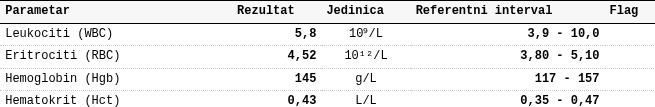
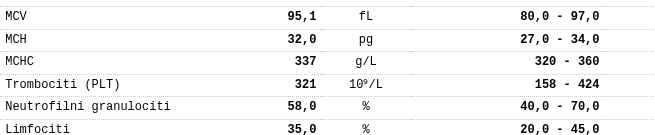

In [20]:
table = data.table_box(PAGE, "Hematokrit (Hct)")          # the first results table, in page pixels
page_break = data.row_box(PAGE, "Hematokrit (Hct)")[3]    # the bottom of this row
image = data.page_image(PAGE)
end_of_page_1 = image.crop((table[0], table[1], table[2], page_break))
top_of_page_2 = image.crop((table[0], page_break, table[2], table[3]))
show.page_break(end_of_page_1, top_of_page_2)

In [21]:
def read_with_docling(picture, name):
    """Docling reads files, so the picture is saved first, with white space around it as a page margin."""
    path = Path("outputs") / f"{name}.png"
    path.parent.mkdir(exist_ok=True)
    ImageOps.expand(picture, border=40, fill="white").save(path)
    return data.from_docling(converter.convert(path).document)


show.markdown(read_with_docling(top_of_page_2, "top_of_page_2"), "Docling on the top of page 2")

MCV,"95,1",fL,"80,0 - 97,0",
MCH,"32,0",pg,"27,0 - 34,0",
MCHC,337,g/L,,320 - 360
Trombociti (PLT),321,109/L,,158- 424
Neutrofilni granulociti,"58,0",%,"40,0 - 70,0",
Limfociti,"35,0",%,,"20,0 - 45,0"


The first row of data became the header. The repair: stack both parts into one image and run the same
parser again, so that the header travels with the rows. Nothing is retrained.


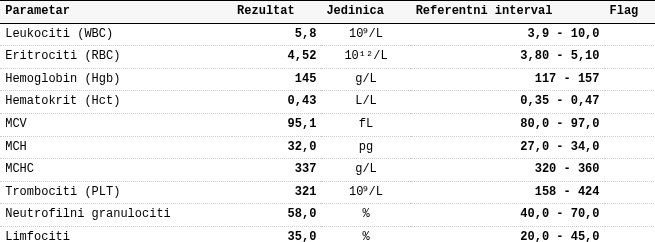

Parametar,Rezultat,Jedinica,Referentni interval,Flag
Leukociti (WBC),"5,8",109/L,"3,9 -","10,0"
Eritrociti (RBC),"4,52",1012/L,"3,80 - 5,10",
Hemoglobin (Hgb),145,g/L,,117 - 157
Hematokrit (Hct),"0,43",L/L,"0,35 - 0,47",
MCV,"95,1",fL,"80,0 - 97,0",
MCH,"32,0",pg,"27,0 - 34, 0",
MCHC,337,g/L,320 - 360,
Trombociti (PLT),321,109/L,158- 424,
Neutrofilni granulociti,"58,0",%,"40,0 - 70,0",
Limfociti,"35,0",%,"20,0 - 45,0",


In [22]:
both_parts = Image.new("RGB", (end_of_page_1.width, end_of_page_1.height + top_of_page_2.height), "white")
both_parts.paste(end_of_page_1, (0, 0))
both_parts.paste(top_of_page_2, (0, end_of_page_1.height))
show.image(both_parts, "Both parts stacked")
show.markdown(read_with_docling(both_parts, "both_parts"), "Docling on both parts stacked")

## 8. Try your own document

Set `MY_FILE` to the path of a PDF or an image and run the cell. On Colab, upload the file with the file
browser on the left; it lands in `/content/`, so the path is `/content/<file name>`.

- Docling: https://github.com/docling-project/docling
- PaddleOCR-VL: https://huggingface.co/PaddlePaddle/PaddleOCR-VL-1.6
- Qwen2.5-VL: https://huggingface.co/Qwen/Qwen2.5-VL-3B-Instruct

In [23]:
MY_FILE = "path/to/your/document.pdf"

if Path(MY_FILE).exists():
    show.parse(data.from_docling(converter.convert(MY_FILE).document))
else:
    print("Set MY_FILE to the path of a PDF or an image, then run this cell again.")

Set MY_FILE to the path of a PDF or an image, then run this cell again.
